In [1]:
import json
import pandas as pd

with open("api_troll_farm.json", encoding="utf-8") as file:
    records = json.load(file)

In [2]:
rows = []

for record in records:
    activity = record.get("activity") or {}
    for relacion, destinos in activity.items():
        if destinos is None:
            continue
        for destino in destinos:
            rows.append({
                "Origen": record["account_id"],
                "Destino": destino,
                "Relacion": relacion,
            })

df_final = pd.DataFrame(rows, columns=["Origen", "Destino", "Relacion"])
df_final["Origen"] = df_final["Origen"].str.lower()
df_final["Destino"] = df_final["Destino"].str.lower()
df_final = df_final.drop_duplicates(subset=["Origen", "Destino", "Relacion"], keep="first")
df_final = df_final[df_final["Origen"] != df_final["Destino"]]
display(df_final)

,Origen,Destino,Relacion
0,troll_bot_1,real_user_11,retweets
3,real_user_14,real_user_15,retweets
4,real_user_14,real_user_11,retweets
5,real_user_13,real_user_3,retweets
6,real_user_13,real_user_9,retweets
7,troll_bot_5,real_user_12,retweets
8,troll_bot_5,troll_bot_1,retweets
11,real_user_12,real_user_15,retweets
12,real_user_11,real_user_14,retweets
13,real_user_11,real_user_6,retweets


In [3]:
metadata_rows = []

for record in records:
    metadata = record.get("metadata") or {}
    metadata_rows.append({
        "Origen": record.get("account_id"),
        "last_ip": metadata.get("last_ip"),
        "payment_hash": metadata.get("payment_hash"),
    })

df_metadata = pd.DataFrame(metadata_rows, columns=["Origen", "last_ip", "payment_hash"])
df_metadata["Origen"] = df_metadata["Origen"].str.lower()
df_metadata = df_metadata.drop_duplicates(subset=["Origen"], keep="first")
display(df_metadata)

,Origen,last_ip,payment_hash
0,troll_bot_1,104.28.19.112,VISA-4455-XXXX-9090
1,real_user_14,189.168.1.196,MC-8573-XXXX-1111
2,real_user_13,189.168.1.184,None
3,troll_bot_5,104.28.19.112,VISA-4455-XXXX-9090
4,real_user_12,189.168.1.51,MC-4432-XXXX-1111
5,real_user_11,189.168.1.231,MC-5554-XXXX-1111
6,real_user_15,189.168.1.186,None
7,real_user_8,189.168.1.246,MC-5803-XXXX-1111
8,real_user_10,189.168.1.68,None
10,troll_bot_4,104.28.19.112,VISA-4455-XXXX-9090


In [4]:
tarjetas = df_metadata.dropna(subset=["payment_hash"])
pares = tarjetas.merge(tarjetas, on="payment_hash", suffixes=("_o", "_d"))
pares = pares[pares["Origen_o"] != pares["Origen_d"]]

df_tarjeta = pd.DataFrame({
    "Origen": pares["Origen_o"],
    "Destino": pares["Origen_d"],
    "Relacion": "Misma_Tarjeta",
})
display(df_tarjeta)

,Origen,Destino,Relacion
1,troll_bot_1,troll_bot_5,Misma_Tarjeta
2,troll_bot_1,troll_bot_4,Misma_Tarjeta
3,troll_bot_1,troll_bot_6,Misma_Tarjeta
4,troll_bot_1,troll_bot_3,Misma_Tarjeta
5,troll_bot_1,troll_bot_2,Misma_Tarjeta
7,troll_bot_5,troll_bot_1,Misma_Tarjeta
9,troll_bot_5,troll_bot_4,Misma_Tarjeta
10,troll_bot_5,troll_bot_6,Misma_Tarjeta
11,troll_bot_5,troll_bot_3,Misma_Tarjeta
12,troll_bot_5,troll_bot_2,Misma_Tarjeta


In [5]:
df_maestra = pd.concat([df_final, df_tarjeta], ignore_index=True)
display(df_maestra)

,Origen,Destino,Relacion
0,troll_bot_1,real_user_11,retweets
1,real_user_14,real_user_15,retweets
2,real_user_14,real_user_11,retweets
3,real_user_13,real_user_3,retweets
4,real_user_13,real_user_9,retweets
...,...,...,...
62,troll_bot_2,troll_bot_1,Misma_Tarjeta
63,troll_bot_2,troll_bot_5,Misma_Tarjeta
64,troll_bot_2,troll_bot_4,Misma_Tarjeta
65,troll_bot_2,troll_bot_6,Misma_Tarjeta


In [6]:
import networkx as nx
import matplotlib.pyplot as plt

MG = nx.MultiDiGraph()
for _, fila in df_maestra.iterrows():
    MG.add_edge(fila["Origen"], fila["Destino"], Relacion=fila["Relacion"])

print("Nodos:", MG.number_of_nodes())
print("Aristas:", MG.number_of_edges())

Nodos: 21
Aristas: 67


In [7]:
aristas_tarjeta = [
    (u, v) for u, v, d in MG.edges(data=True) if d["Relacion"] == "Misma_Tarjeta"
]

G_tarjeta = nx.Graph()
G_tarjeta.add_edges_from(aristas_tarjeta)

print("Nodos:", G_tarjeta.number_of_nodes())
print("Aristas:", G_tarjeta.number_of_edges())

Nodos: 6
Aristas: 15


In [8]:
componentes = list(nx.connected_components(G_tarjeta))
for i, comp in enumerate(componentes, start=1):
    print(f"Componente {i}: {sorted(comp)}")

Componente 1: ['troll_bot_1', 'troll_bot_2', 'troll_bot_3', 'troll_bot_4', 'troll_bot_5', 'troll_bot_6']


In [10]:
pos = nx.spring_layout(MG.to_undirected(), seed=42, k=0.8)

def dibujar(G, titulo, color):
    plt.figure(figsize=(9, 7))
    nx.draw_networkx_nodes(G, pos, node_size=450, node_color="#cfe8f3", edgecolors="#333")
    nx.draw_networkx_labels(G, pos, font_size=7)
    nx.draw_networkx_edges(G, pos, edge_color=color, width=1.2, alpha=0.7, node_size=450)
    plt.title(titulo)
    plt.axis("off")
    plt.show()

NameError: name 'nx' is not defined

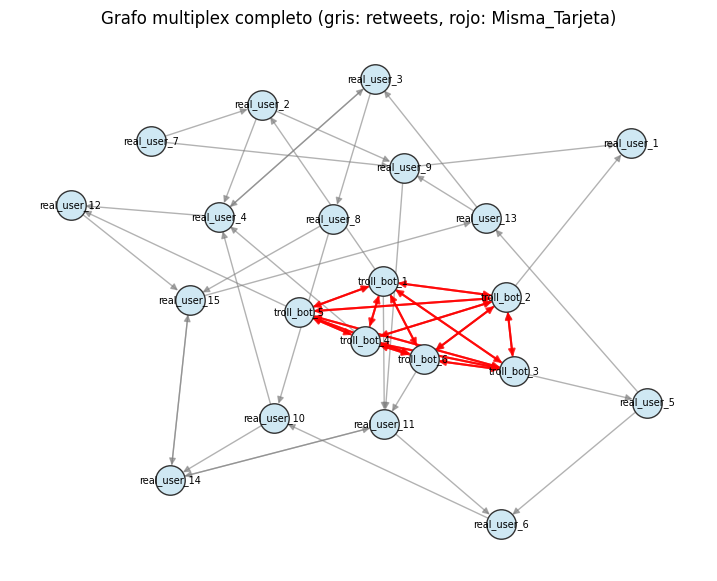

In [10]:
plt.figure(figsize=(9, 7))
nx.draw_networkx_nodes(MG, pos, node_size=450, node_color="#cfe8f3", edgecolors="#333")
nx.draw_networkx_labels(MG, pos, font_size=7)
nx.draw_networkx_edges(
    MG, pos,
    edgelist=[(u, v) for u, v, d in MG.edges(data=True) if d["Relacion"] == "retweets"],
    edge_color="gray", width=1.0, alpha=0.6, node_size=450,
)
nx.draw_networkx_edges(
    MG, pos,
    edgelist=[(u, v) for u, v, d in MG.edges(data=True) if d["Relacion"] == "Misma_Tarjeta"],
    edge_color="red", width=1.5, alpha=0.8, node_size=450,
)
plt.title("Grafo multiplex completo (gris: retweets, rojo: Misma_Tarjeta)")
plt.axis("off")
plt.show()

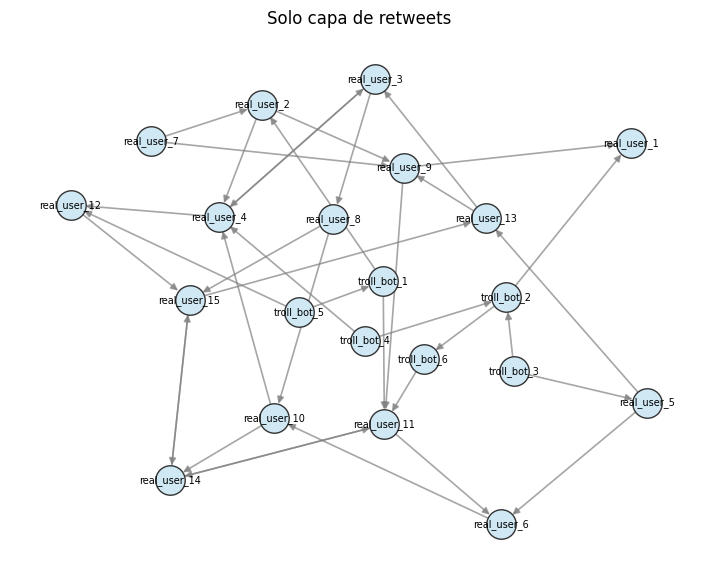

In [11]:
G_solo_retweets = nx.MultiDiGraph()
G_solo_retweets.add_nodes_from(MG.nodes())
G_solo_retweets.add_edges_from((u, v) for u, v, d in MG.edges(data=True) if d["Relacion"] == "retweets")

dibujar(G_solo_retweets, "Solo capa de retweets", "gray")

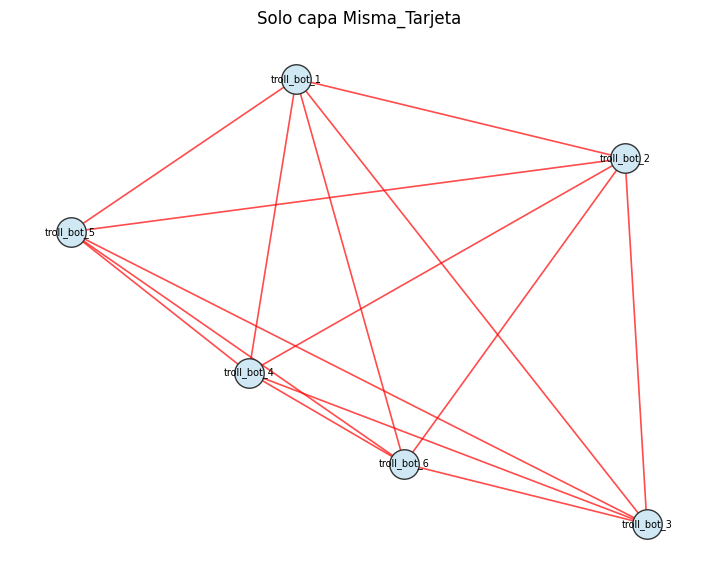

In [12]:
dibujar(G_tarjeta, "Solo capa Misma_Tarjeta", "red")

## Veredicto

**1. Bots del anillo de fraude (account_id):** `troll_bot_1`, `troll_bot_2`, `troll_bot_3`, `troll_bot_4`, `troll_bot_5`, `troll_bot_6` (en el JSON aparecen en mayúsculas: `TROLL_BOT_1`, etc.).

**2. Hash de tarjeta a bloquear:** `VISA-4455-XXXX-9090`

**3. Entrenamiento del modelo:** 
En la matriz x se ponen todas las variables calculadas de la capa misma_tarjeta, donde podemos sacar dependiendo del usuario y su ip y otroas variables, si está con el valor de misma tarjeta y cuantas otras comparte con misma tarjeta, si su valor es null porque no ha brindado tarjeta o si solo a retweets y la etiqueta y sería si son bots o no.